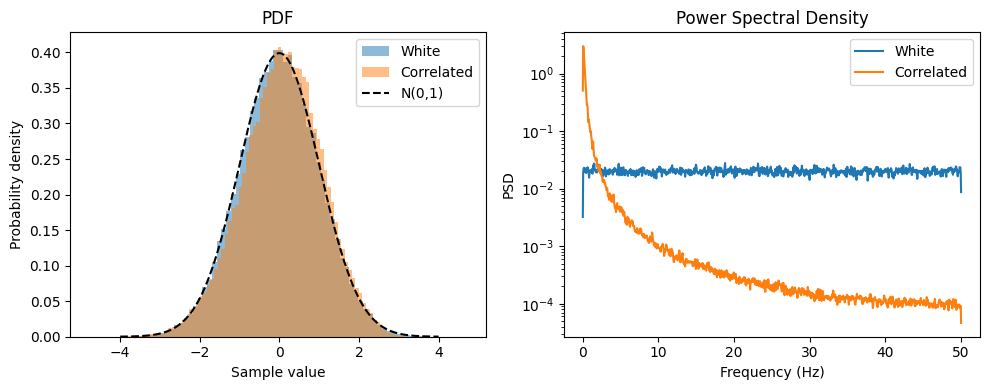

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.stats import norm

N = 100000
fs = 100.0

# White Gaussian noise
white = np.random.randn(N)

# Correlated Gaussian noise (AR(1))
alpha = 0.99
corr = np.zeros(N)

for k in range(1, N):
    corr[k] = alpha * corr[k-1] + np.random.randn()

# Normalise to unit variance
white /= np.std(white)
corr /= np.std(corr)

# PSDs
f1, P1 = signal.welch(white, fs=fs, nperseg=2048)
f2, P2 = signal.welch(corr, fs=fs, nperseg=2048)

# PDFs
x = np.linspace(-4, 4, 400)

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.hist(white, bins=80, density=True, alpha=0.5, label="White")
plt.hist(corr, bins=80, density=True, alpha=0.5, label="Correlated")
plt.plot(x, norm.pdf(x), 'k--', label='N(0,1)')
plt.xlabel("Sample value")
plt.ylabel("Probability density")
plt.title("PDF")
plt.legend()

plt.subplot(1,2,2)
plt.semilogy(f1, P1, label="White")
plt.semilogy(f2, P2, label="Correlated")
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD")
plt.title("Power Spectral Density")
plt.legend()

plt.tight_layout()
plt.show()